# 07 · Streaming  🟡 Intermediate

Users hate waiting on a blank screen. LangGraph can stream several kinds of events:

| `stream_mode` | You get | Typical use |
|---|---|---|
| `"values"` | full state after each step | debugging |
| `"updates"` | what each node returned | progress UI |
| `"messages"` | LLM tokens + metadata (which node) | chat typing effect |
| `"custom"` | anything you emit with `get_stream_writer()` | progress bars, logs |

We use `effort="low"` here so the demo runs fast.

In [1]:
from helpers import get_llm, show_graph

llm = get_llm(effort="low")

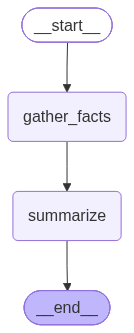

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.config import get_stream_writer

class State(TypedDict):
    topic: str
    facts: str
    summary: str

def gather_facts(state: State):
    writer = get_stream_writer()
    writer({"progress": "🔎 gathering facts..."})
    facts = llm.invoke(f"List 3 short facts about {state['topic']}. Plain bullet list.").text
    writer({"progress": "✅ facts ready"})
    return {"facts": facts}

def summarize(state: State):
    get_stream_writer()({"progress": "✍️ summarizing..."})
    return {"summary": llm.invoke(f"Summarize in one sentence:\n{state['facts']}").text}

b = StateGraph(State)
b.add_node(gather_facts); b.add_node(summarize)
b.add_edge(START, "gather_facts"); b.add_edge("gather_facts", "summarize"); b.add_edge("summarize", END)
graph = b.compile()
show_graph(graph)
inputs = {"topic": "octopuses"}

## 1. `values`: full state after every step

In [3]:
for state in graph.stream(inputs, stream_mode="values"):
    print(list(state.keys()))

['topic']


['topic', 'facts']


['topic', 'facts', 'summary']


## 2. `updates`: only what changed, per node

In [4]:
for update in graph.stream(inputs, stream_mode="updates"):
    for node, changes in update.items():
        print(f"[{node}] updated keys: {list(changes)}")

[gather_facts] updated keys: ['facts']


[summarize] updated keys: ['summary']


## 3. `messages`: token-by-token LLM output

Works even though nodes call `llm.invoke()`: LangGraph captures tokens through callbacks.
`metadata["langgraph_node"]` tells you which node is talking.

In [5]:
current = None
for chunk, metadata in graph.stream(inputs, stream_mode="messages"):
    node = metadata["langgraph_node"]
    if node != current:
        print(f"\n\n--- {node} ---")
        current = node
    print(chunk.text, end="", flush=True)



--- gather_facts ---


- Octopuses have three

 hearts.


-

 Their blood is blue because

...

 blood due to copper-based

 hemocyanin, and

 most of their neurons in

 their arms rather than their central

 brain.

## 4. `custom`: your own events

In [6]:
for event in graph.stream(inputs, stream_mode="custom"):
    print(event)

{'progress': '🔎 gathering facts...'}


{'progress': '✅ facts ready'}
{'progress': '✍️ summarizing...'}


## 5. Several modes at once

With a list of modes you get `(mode, payload)` tuples.

In [7]:
for mode, payload in graph.stream(inputs, stream_mode=["custom", "updates"]):
    if mode == "custom":
        print("PROGRESS:", payload["progress"])
    else:
        print("UPDATE  :", list(payload))

PROGRESS: 🔎 gathering facts...


PROGRESS: ✅ facts ready
UPDATE  : ['gather_facts']
PROGRESS: ✍️ summarizing...


UPDATE  : ['summarize']


## 6. Async streaming (for web servers like FastAPI)

Jupyter supports top-level `await`, so you can try the async API directly.

In [8]:
async for chunk, metadata in graph.astream({"topic": "black holes"}, stream_mode="messages"):
    if metadata["langgraph_node"] == "summarize":
        print(chunk.text, end="", flush=True)

Black holes,

 which us

ually form when

 massive stars collapse at

 the end of their lives, tr

...

 horizon, and a superm

assive one called Sagitt

arius A* lies at the

 center of the Milky Way

.

## 7. Streaming an agent's tool calls

In [9]:
from langchain_core.tools import tool
from langchain.agents import create_agent

@tool
def get_population(city: str) -> str:
    """Return the population of a city."""
    return {"delhi": "33 million", "london": "9 million"}.get(city.lower(), "unknown")

agent = create_agent(llm, tools=[get_population])
for update in agent.stream({"messages": [("user", "Compare the populations of Delhi and London.")]}, stream_mode="updates"):
    for node, changes in update.items():
        for m in changes["messages"]:
            if getattr(m, "tool_calls", None):
                print(f"[{node}] 🔧 calling", [(c["name"], c["args"]) for c in m.tool_calls])
            elif m.type == "tool":
                print(f"[{node}] 📦 result:", m.text)
            else:
                print(f"[{node}] 💬", m.text)

[model] 🔧 calling [('get_population', {'city': 'Delhi'}), ('get_population', {'city': 'London'})]
[tools] 📦 result: 33 million
[tools] 📦 result: 9 million


[model] 💬 Delhi has about 33 million people and London has about 9 million.

- **Difference:** Delhi has about 24 million more people.
- **Ratio:** Delhi's population is about 3.7 times London's.

Delhi's number probably covers the whole urban area, while London's is closer to the city itself.


## ✅ Recap
* Pick the stream mode by what your UI needs; combine several with a list.
* `messages` mode = typing effect; filter by `metadata["langgraph_node"]`.
* `get_stream_writer()` emits custom progress events from inside nodes (and tools).
* `astream` for async apps.